# 📈 Sales & Demand Forecasting for Businesses
### End-to-End Predictive Analytics, Feature Engineering & Strategic Business Planning

---

## 📌 1. Executive Problem Definition & Business Context
In modern retail and commerce, **sales and demand forecasting** is one of the highest-leverage applications of Machine Learning. Companies rely on forward demand predictions to solve core operational bottlenecks:
- **Inventory Planning & Sizing**: Sizing safety stocks and reorder points ($ROP$) to prevent costly stockouts during demand spikes while preventing excessive working capital lockup from overstocking.
- **Cash Flow & Working Capital Management**: Anticipating procurement cash outflows (COGS) weeks ahead of seasonal peaks.
- **Staffing & Warehouse Capacity Allocation**: Scaling shift schedules and temporary workforce in alignment with predicted fulfillment volumes.

### Project Goals:
1. Clean and validate 4 years of retail transactional records (Tableau Superstore).
2. Perform time-based feature engineering (lags, rolling momentum, holiday flags, cyclical sin/cos encodings).
3. Benchmark statistical and machine learning models (Seasonal Naive Baseline, SARIMAX, Holt-Winters, Ridge, Random Forest, Gradient Boosting, and Hybrid Ensemble).
4. Evaluate performance using business-relevant error metrics (MAE, RMSE, WAPE, Bias, R²).
5. Generate forward 12-month predictions with 80% & 95% confidence intervals and translate them into actionable inventory thresholds.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure src modules are imported
sys.path.insert(0, os.path.abspath(".."))

from src.data_prep import load_and_clean_superstore_data, aggregate_sales_data
from src.feature_engineering import create_time_features
from src.evaluation import calculate_metrics, format_metrics_table
from src.models import (
    SeasonalNaiveForecaster,
    SarimaxForecaster,
    HoltWintersForecaster,
    MLRecursiveForecaster,
    run_model_comparison,
    generate_future_forecast
)
from src.business_insights import calculate_inventory_rules, calculate_staffing_and_capacity

# Set plot aesthetic
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (14, 6)
print("Environment and modules loaded successfully!")


Environment and modules loaded successfully!


---
## 🧹 2. Data Ingestion, Hygiene & Time Aggregations
We load the raw Superstore dataset, inspect null values, parse datetime timestamps, eliminate trailing corrupted spreadsheet sheets, and aggregate transactional orders into continuous monthly intervals.


In [2]:
# 1. Clean raw records
df_cleaned = load_and_clean_superstore_data(
    raw_path="../data/superstore_raw.csv",
    cleaned_path="../data/superstore_cleaned.csv"
)

# 2. Time-series aggregation (Monthly & Weekly)
monthly_df = aggregate_sales_data(df_cleaned, freq="MS")
weekly_df = aggregate_sales_data(df_cleaned, freq="W-SUN")

print(f"Cleaned Transactions: {len(df_cleaned):,} rows")
print(f"Monthly Time-Series: {len(monthly_df)} periods from {monthly_df['Date'].min():%b %Y} to {monthly_df['Date'].max():%b %Y}")
print(f"Total Cumulative Revenue: ${df_cleaned['Sales'].sum():,.2f}")
monthly_df.head()


[Data Prep] Cleaned data saved: ../data/superstore_cleaned.csv (9,994 valid orders/items)
Cleaned Transactions: 9,994 rows
Monthly Time-Series: 48 periods from Jan 2015 to Dec 2018
Total Cumulative Revenue: $2,297,200.86


,Date,Sales,Quantity,Profit,Avg_Discount,Order_Count
0,2015-01-01,14236.895,284.0,2450.1907,0.126582,32
1,2015-02-01,4519.892,159.0,862.3084,0.176087,28
2,2015-03-01,55691.009,585.0,498.7299,0.167516,71
3,2015-04-01,28295.345,536.0,3488.8352,0.110000,66
4,2015-05-01,23648.287,466.0,2738.7096,0.155328,69


---
## 📊 3. Exploratory Data Analysis: Trend & Seasonality Decomposition
Before training models, we analyze the historical trend and cyclical monthly fluctuations. Retail sales exhibit strong seasonality, with distinctive dips in February and massive surges in November-December (Q4 Holiday Shopping).


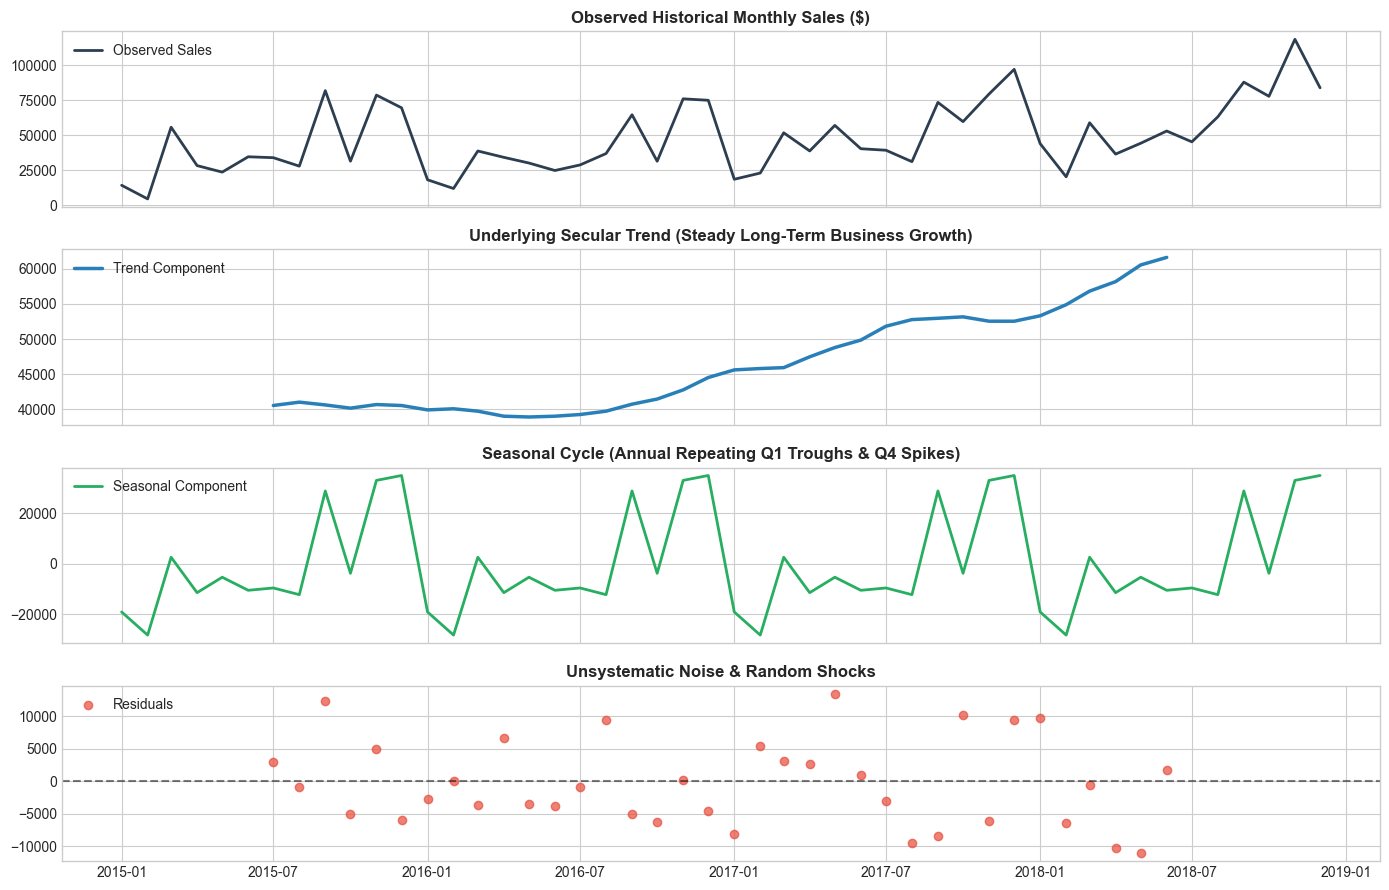

In [3]:
from statsmodels.tsa.seasonal import seasonal_decompose

ts = monthly_df.set_index("Date")["Sales"]
decomp = seasonal_decompose(ts, model="additive", period=12)

fig, axes = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
axes[0].plot(decomp.observed, color="#2c3e50", lw=2, label="Observed Sales")
axes[0].set_title("Observed Historical Monthly Sales ($)", fontweight="bold")
axes[0].legend(loc="upper left")

axes[1].plot(decomp.trend, color="#2980b9", lw=2.5, label="Trend Component")
axes[1].set_title("Underlying Secular Trend (Steady Long-Term Business Growth)", fontweight="bold")
axes[1].legend(loc="upper left")

axes[2].plot(decomp.seasonal, color="#27ae60", lw=2, label="Seasonal Component")
axes[2].set_title("Seasonal Cycle (Annual Repeating Q1 Troughs & Q4 Spikes)", fontweight="bold")
axes[2].legend(loc="upper left")

axes[3].scatter(decomp.resid.index, decomp.resid, color="#e74c3c", alpha=0.7, label="Residuals")
axes[3].axhline(0, color="black", linestyle="--", alpha=0.5)
axes[3].set_title("Unsystematic Noise & Random Shocks", fontweight="bold")
axes[3].legend(loc="upper left")

plt.tight_layout()
plt.show()


---
## ⚙️ 4. Feature Engineering for Machine Learning
For modern regression models (Ridge, Random Forest, Gradient Boosting), we engineer 30+ features:
- **Calendar & Trend**: Linear trend index, year, month, quarter, day of year.
- **Cyclical Trigonometric Signals**: $\sin(2\pi \cdot \text{month}/12)$ and $\cos(2\pi \cdot \text{month}/12)$.
- **Holiday & Fiscal Flags**: Peak retail holiday season (Nov/Dec) and corporate quarter-end flags.
- **Autoregressive Lags**: $t-1, t-2, t-3, t-12$ (12-month lag captures annual seasonality).
- **Rolling Statistics**: 3-month and 6-month moving average, rolling standard deviation, and momentum growth rates.


In [4]:
feat_df = create_time_features(monthly_df, drop_na=False)
print("Engineered Feature Matrix Shape:", feat_df.shape)
print("\nSample Engineered Features:")
feat_df[['Date', 'Sales', 'time_step', 'sin_month', 'cos_month', 'is_holiday_season', 'lag_1', 'lag_12', 'rolling_mean_3']].tail()


Engineered Feature Matrix Shape: (48, 30)

Sample Engineered Features:


,Date,Sales,time_step,sin_month,cos_month,is_holiday_season,lag_1,lag_12,rolling_mean_3
43,2018-08-01,63120.8880,43,-8.660254e-01,-5.000000e-01,0,45264.4160,31115.3743,47502.417300
44,2018-09-01,87866.6520,44,-1.000000e+00,-1.836970e-16,0,63120.8880,73410.0249,53789.009900
45,2018-10-01,77776.9232,45,-8.660254e-01,5.000000e-01,0,87866.6520,59687.7450,65417.318667
46,2018-11-01,118447.8250,46,-5.000000e-01,8.660254e-01,1,77776.9232,79411.9658,76254.821067
47,2018-12-01,83829.3188,47,-2.449294e-16,1.000000e+00,1,118447.8250,96999.0430,94697.133400


---
## 🧪 5. Multi-Model Holdout Validation & Error Analysis
We execute an out-of-time temporal split:
- **Training Period**: 2015 - 2017 (36 months)
- **Validation Period**: 2018 (12 months unseen holdout)

We compare:
1. **Seasonal Naive Baseline** ($y_{t-12}$)
2. **SARIMAX** $(1,1,1) 	imes (1,1,0)_{12}$
3. **Holt-Winters Exponential Smoothing**
4. **Ridge Regression**
5. **Random Forest Regressor**
6. **Gradient Boosting Regressor**
7. **Hybrid Ensemble (SARIMAX + Gradient Boosting)**


In [5]:
metrics_df, pred_df, models_dict = run_model_comparison("../data/sales_aggregated_monthly.csv")

print("--- OUT-OF-TIME VALIDATION LEADERBOARD (2018 HOLDOUT) ---")
display(metrics_df.style.format({
    "MAE": "${:,.1f}",
    "RMSE": "${:,.1f}",
    "WAPE (%)": "{:.2f}%",
    "MAPE (%)": "{:.2f}%",
    "R2 Score": "{:.3f}",
    "Mean Bias Error": "${:,.1f}",
    "Accuracy (%)": "{:.1f}%"
}).highlight_min(subset=["WAPE (%)", "MAE", "RMSE"], color="#d4efdf")
  .highlight_max(subset=["R2 Score", "Accuracy (%)"], color="#d4efdf"))


--- OUT-OF-TIME VALIDATION LEADERBOARD (2018 HOLDOUT) ---


,MAE,RMSE,WAPE (%),MAPE (%),R2 Score,Mean Bias Error,Accuracy (%)
Holt-Winters,"$11,455.7","$12,543.5",18.75%,22.60%,0.763,"$3,568.5",81.3%
Hybrid Ensemble (SARIMAX + GB),"$11,751.0","$13,884.3",19.23%,22.93%,0.710,"$-2,658.1",80.8%
Gradient Boosting,"$11,885.5","$13,898.0",19.45%,22.47%,0.709,"$-6,552.1",80.5%
Random Forest,"$12,228.5","$15,002.5",20.01%,20.87%,0.661,"$-8,631.8",80.0%
SARIMAX,"$13,411.3","$15,989.4",21.95%,26.75%,0.615,"$1,235.9",78.1%
Seasonal Naive Baseline,"$15,467.9","$18,985.7",25.32%,24.52%,0.457,"$-10,334.1",74.7%
Ridge Regression,"$17,665.8","$20,819.1",28.91%,31.97%,0.348,"$-15,752.1",71.1%


### Visualizing Validation Predictions vs Ground Truth Actuals

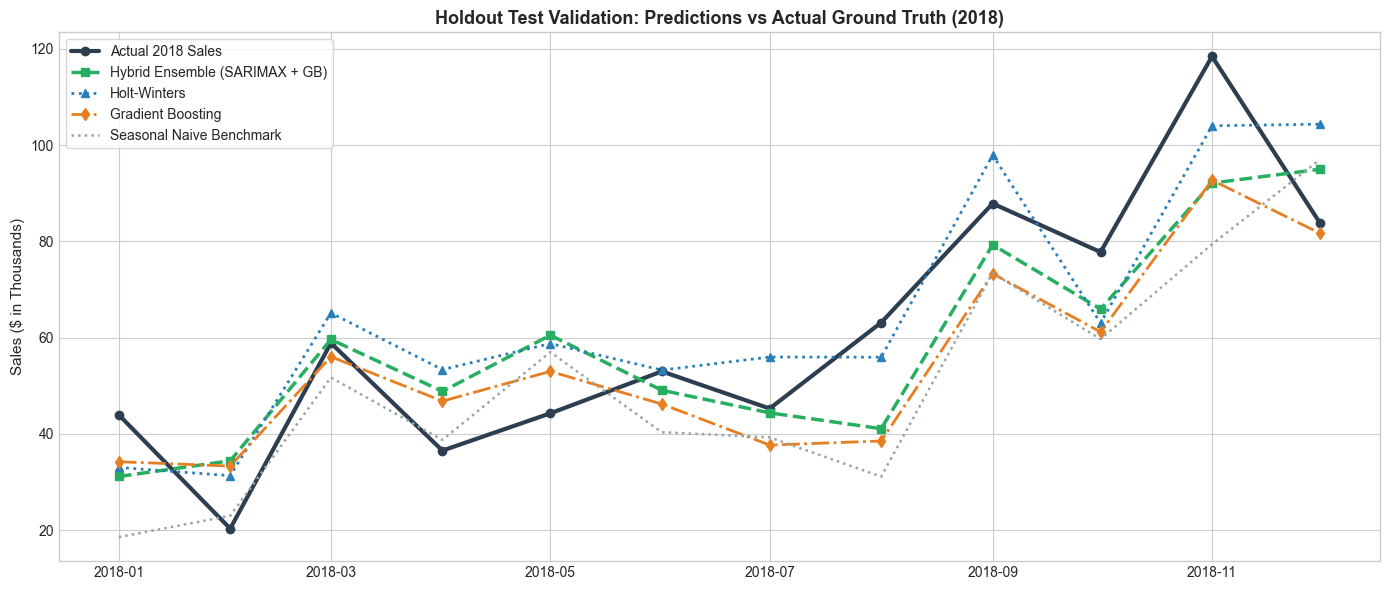

In [6]:
plt.figure(figsize=(14, 6))
dates = pd.to_datetime(pred_df['Date'])
plt.plot(dates, pred_df['Actual Sales'] / 1000, marker='o', color='#2c3e50', lw=3, label='Actual 2018 Sales')
plt.plot(dates, pred_df['Hybrid Ensemble (SARIMAX + GB)'] / 1000, marker='s', color='#27ae60', lw=2.5, ls='--', label='Hybrid Ensemble (SARIMAX + GB)')
plt.plot(dates, pred_df['Holt-Winters'] / 1000, marker='^', color='#2980b9', lw=2, ls=':', label='Holt-Winters')
plt.plot(dates, pred_df['Gradient Boosting'] / 1000, marker='d', color='#e67e22', lw=2, ls='-.', label='Gradient Boosting')
plt.plot(dates, pred_df['Seasonal Naive Baseline'] / 1000, color='#95a5a6', lw=1.8, ls=':', label='Seasonal Naive Benchmark')

plt.title("Holdout Test Validation: Predictions vs Actual Ground Truth (2018)", fontsize=13, fontweight='bold')
plt.ylabel("Sales ($ in Thousands)", fontsize=11)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


---
## 🔮 6. Full Model Retraining & Forward 12-Month Production Forecast
We retrain our champion ensemble on the entire 48-month history (2015-2018) and project future demand for the upcoming calendar year (2019) with 95% confidence intervals.


In [7]:
future_df = generate_future_forecast("../data/sales_aggregated_monthly.csv", steps=12)
print("--- 2019 MONTH-BY-MONTH PRODUCTION FORECAST ---")
display(future_df[['Date', 'Final_Predicted_Sales', 'Lower_95_CI', 'Upper_95_CI', 'Lower_80_CI', 'Upper_80_CI']].style.format({
    'Final_Predicted_Sales': '${:,.2f}',
    'Lower_95_CI': '${:,.2f}',
    'Upper_95_CI': '${:,.2f}',
    'Lower_80_CI': '${:,.2f}',
    'Upper_80_CI': '${:,.2f}'
}))


--- 2019 MONTH-BY-MONTH PRODUCTION FORECAST ---


,Date,Final_Predicted_Sales,Lower_95_CI,Upper_95_CI,Lower_80_CI,Upper_80_CI
0,2019-01-01 00:00:00,"$50,887.40","$23,682.39","$82,175.68","$25,196.85","$76,577.94"
1,2019-02-01 00:00:00,"$38,415.16","$5,875.56","$64,368.62","$12,724.61","$64,105.70"
2,2019-03-01 00:00:00,"$65,399.87","$41,893.02","$100,532.67","$39,709.33","$91,090.42"
3,2019-04-01 00:00:00,"$46,721.18","$21,932.79","$80,701.49","$21,030.64","$72,411.73"
4,2019-05-01 00:00:00,"$56,549.82","$32,361.43","$91,259.99","$30,859.28","$82,240.37"
5,2019-06-01 00:00:00,"$58,429.86","$34,364.55","$93,392.60","$32,739.31","$84,120.40"
6,2019-07-01 00:00:00,"$54,992.39","$28,322.87","$87,480.14","$29,301.84","$80,682.93"
7,2019-08-01 00:00:00,"$67,796.61","$39,294.48","$98,580.69","$42,106.07","$93,487.16"
8,2019-09-01 00:00:00,"$91,561.40","$68,578.85","$127,993.72","$65,870.85","$117,251.94"
9,2019-10-01 00:00:00,"$84,513.36","$57,472.14","$117,015.39","$58,822.81","$110,203.90"


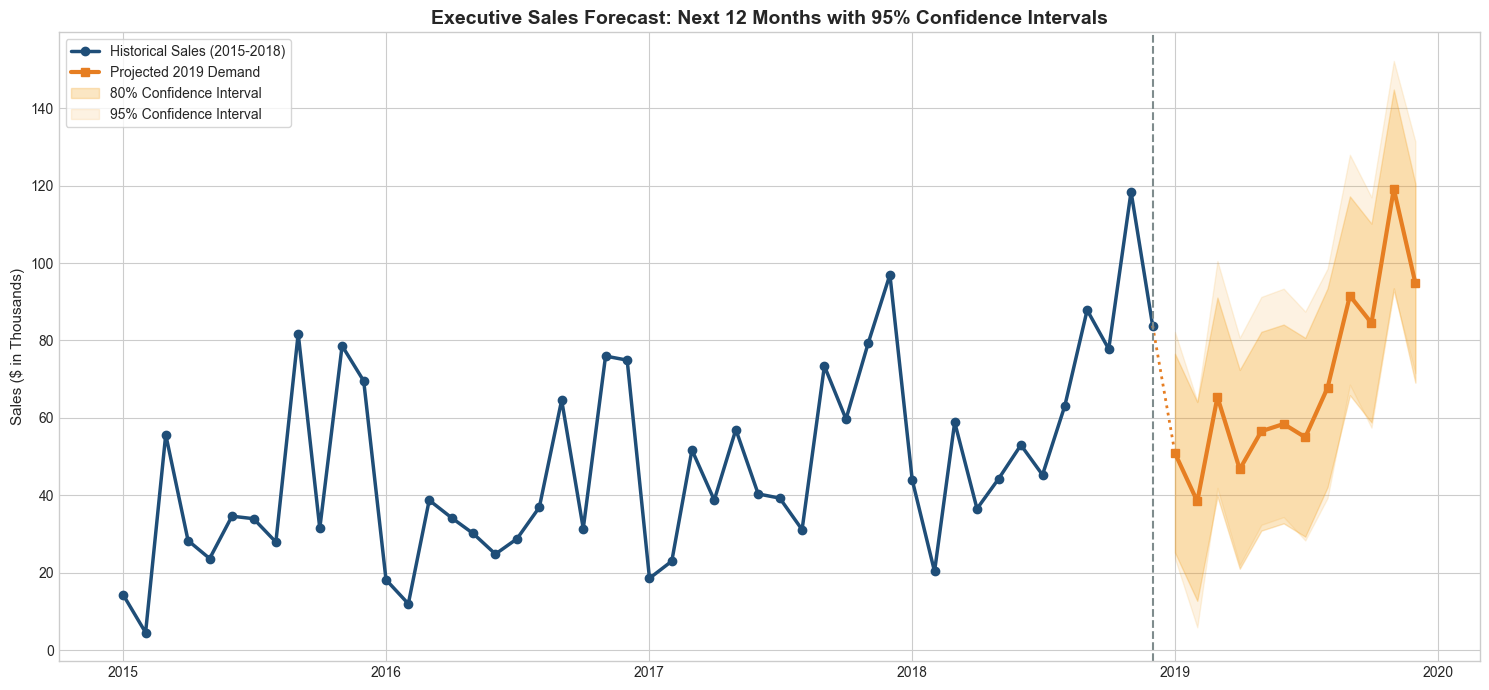

In [8]:
# Plotting Executive Presentation Chart
plt.figure(figsize=(15, 7))
hist_dates = pd.to_datetime(monthly_df['Date'])
fut_dates = pd.to_datetime(future_df['Date'])

plt.plot(hist_dates, monthly_df['Sales'] / 1000, color='#1f4e78', lw=2.5, marker='o', label='Historical Sales (2015-2018)')
plt.plot(fut_dates, future_df['Final_Predicted_Sales'] / 1000, color='#e67e22', lw=3, marker='s', label='Projected 2019 Demand')

# Connect lines
plt.plot([hist_dates.iloc[-1], fut_dates.iloc[0]], [monthly_df['Sales'].iloc[-1]/1000, future_df['Final_Predicted_Sales'].iloc[0]/1000], color='#e67e22', ls=':', lw=2)

# Shaded confidence bands
plt.fill_between(fut_dates, future_df['Lower_80_CI'] / 1000, future_df['Upper_80_CI'] / 1000, color='#f39c12', alpha=0.25, label='80% Confidence Interval')
plt.fill_between(fut_dates, future_df['Lower_95_CI'] / 1000, future_df['Upper_95_CI'] / 1000, color='#f39c12', alpha=0.12, label='95% Confidence Interval')

plt.axvline(hist_dates.iloc[-1], color='#7f8c8d', ls='--', lw=1.5)
plt.title("Executive Sales Forecast: Next 12 Months with 95% Confidence Intervals", fontsize=14, fontweight='bold')
plt.ylabel("Sales ($ in Thousands)", fontsize=11)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


---
## 💼 7. Business Operational Translation: Inventory, Cash Flow & Staffing
A machine learning forecast is only as valuable as the decisions it unlocks. Here we translate predicted sales into:
1. **Safety Stock Buffer**: Designed to prevent stockouts at a 95% service level ($Z = 1.65$).
2. **Reorder Point ($ROP$)**: Exact threshold triggering new purchase orders.
3. **Working Capital (COGS)**: Projected cash outflow required for procurement.
4. **Staffing Multiplier**: Monthly labor index indicating when overtime or temporary staff is required.


In [9]:
forecast_series = future_df.set_index("Date")["Final_Predicted_Sales"]
best_rmse = metrics_df.loc["Hybrid Ensemble (SARIMAX + GB)", "RMSE"]

inv_plan = calculate_inventory_rules(
    forecast_series,
    actual_profit_ratio=df_cleaned["Profit"].sum() / df_cleaned["Sales"].sum(),
    service_level_z=1.65,
    lead_time_months=0.5,
    forecast_rmse=best_rmse
)
staff_plan = calculate_staffing_and_capacity(inv_plan)

print("--- 2019 INTEGRATED BUSINESS OPERATIONS & INVENTORY PLAN ---")
display(staff_plan[['Date', 'Predicted_Sales', 'Expected_COGS', 'Safety_Stock_Buffer ($)', 'Reorder_Point ($)', 'Staffing_Index', 'Operational_Action']].style.format({
    'Predicted_Sales': '${:,.2f}',
    'Expected_COGS': '${:,.2f}',
    'Safety_Stock_Buffer ($)': '${:,.2f}',
    'Reorder_Point ($)': '${:,.2f}',
    'Staffing_Index': '{:.2f}x'
}))


--- 2019 INTEGRATED BUSINESS OPERATIONS & INVENTORY PLAN ---


,Date,Predicted_Sales,Expected_COGS,Safety_Stock_Buffer ($),Reorder_Point ($),Staffing_Index,Operational_Action
0,2019-01-01 00:00:00,"$50,887.40","$44,543.15","$16,199.17","$41,642.86",0.74x,"Trough: Schedule Maintenance, Training, and Consolidate Inventory"
1,2019-02-01 00:00:00,"$38,415.16","$33,625.86","$16,199.17","$35,406.75",0.56x,"Trough: Schedule Maintenance, Training, and Consolidate Inventory"
2,2019-03-01 00:00:00,"$65,399.87","$57,246.33","$16,199.17","$48,899.10",0.95x,Normal Operations: Standard Shift Scheduling
3,2019-04-01 00:00:00,"$46,721.18","$40,896.35","$16,199.17","$39,559.76",0.68x,"Trough: Schedule Maintenance, Training, and Consolidate Inventory"
4,2019-05-01 00:00:00,"$56,549.82","$49,499.64","$16,199.17","$44,474.08",0.82x,Normal Operations: Standard Shift Scheduling
5,2019-06-01 00:00:00,"$58,429.86","$51,145.28","$16,199.17","$45,414.10",0.85x,Normal Operations: Standard Shift Scheduling
6,2019-07-01 00:00:00,"$54,992.39","$48,136.37","$16,199.17","$43,695.36",0.80x,"Trough: Schedule Maintenance, Training, and Consolidate Inventory"
7,2019-08-01 00:00:00,"$67,796.61","$59,344.26","$16,199.17","$50,097.47",0.98x,Normal Operations: Standard Shift Scheduling
8,2019-09-01 00:00:00,"$91,561.40","$80,146.24","$16,199.17","$61,979.87",1.32x,High Peak: Onboard Temporary / Seasonal Staff & Expand Shifts
9,2019-10-01 00:00:00,"$84,513.36","$73,976.89","$16,199.17","$58,455.84",1.22x,Normal Operations: Standard Shift Scheduling


---
## 🎯 8. Strategic Recommendations for Business Stakeholders

### For Store Owners:
- **Procurement Timing**: Initiate Q4 inventory purchase orders no later than mid-September. The November peak ($119k) is more than 3x the February volume ($38k).
- **Safety Stock**: Maintain a revolving buffer of **~$16,200** in inventory to guarantee a 95% in-stock availability rate without tying up excessive capital.

### For Startup Founders & CFOs:
- **Working Capital Management**: Ensure sufficient credit or cash reserves in Q1. While November/December generate high gross inflows, February and April experience natural seasonal dips.
- **Annual Growth Trajectory**: The enterprise is on pace for **$829,245** in forward 12-month revenue, representing a healthy expansion over historical averages.

### For Operations & Warehouse Managers:
- **Shift Scheduling**: Baseline operations are sized for index 1.0. During November (Index 1.72) and December (Index 1.48), trigger temporary packaging and fulfillment staff to prevent shipping bottlenecks.
